# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

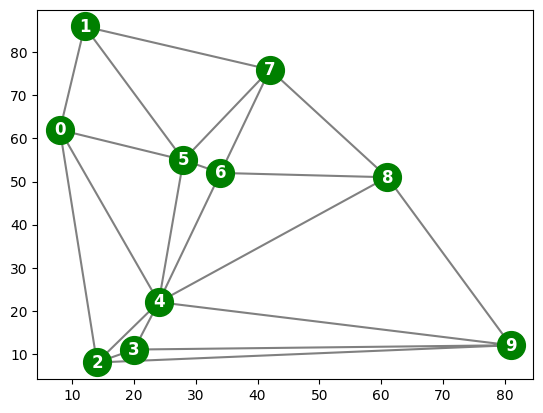

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by 
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [2]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

In [3]:
# BÀI 1 - KIỂM TRA DANH SÁCH ĐỈNH KỀ

for i in range(n):
    print(f"Đỉnh {i}: {sorted(neighbors[i])}")

Đỉnh 0: [np.int32(1), np.int32(2), np.int32(4), np.int32(5)]
Đỉnh 1: [np.int32(0), np.int32(5), np.int32(7)]
Đỉnh 2: [np.int32(0), np.int32(3), np.int32(4), np.int32(9)]
Đỉnh 3: [np.int32(2), np.int32(4), np.int32(9)]
Đỉnh 4: [np.int32(0), np.int32(2), np.int32(3), np.int32(5), np.int32(6), np.int32(8), np.int32(9)]
Đỉnh 5: [np.int32(0), np.int32(1), np.int32(4), np.int32(6), np.int32(7)]
Đỉnh 6: [np.int32(4), np.int32(5), np.int32(7), np.int32(8)]
Đỉnh 7: [np.int32(1), np.int32(5), np.int32(6), np.int32(8)]
Đỉnh 8: [np.int32(4), np.int32(6), np.int32(7), np.int32(9)]
Đỉnh 9: [np.int32(2), np.int32(3), np.int32(4), np.int32(8)]


## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

In [4]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
#domain = ['red', 'blue', 'green']
domains = {}
for v in variables: 
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

In [5]:
# BÀI 1 - KIỂM TRA MÔ HÌNH CSP

print("Số biến:", len(csp["variables"]))
print("Danh sách biến:", csp["variables"])

print("\nMiền giá trị:")
for var in csp["variables"]:
    print(f"Đỉnh {var}: {csp['domains'][var]}")

print("\nSố ràng buộc:", len(csp["constraints"]))
print("Danh sách ràng buộc:")
for constraint in csp["constraints"]:
    print(constraint)

Số biến: 10
Danh sách biến: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

Miền giá trị:
Đỉnh 0: ['red', 'blue', 'green', 'orange']
Đỉnh 1: ['red', 'blue', 'green', 'orange']
Đỉnh 2: ['red', 'blue', 'green', 'orange']
Đỉnh 3: ['red', 'blue', 'green', 'orange']
Đỉnh 4: ['red', 'blue', 'green', 'orange']
Đỉnh 5: ['red', 'blue', 'green', 'orange']
Đỉnh 6: ['red', 'blue', 'green', 'orange']
Đỉnh 7: ['red', 'blue', 'green', 'orange']
Đỉnh 8: ['red', 'blue', 'green', 'orange']
Đỉnh 9: ['red', 'blue', 'green', 'orange']

Số ràng buộc: 21
Danh sách ràng buộc:
('0', '1')
('0', '2')
('0', '4')
('0', '5')
('1', '5')
('1', '7')
('2', '3')
('2', '4')
('2', '9')
('3', '4')
('3', '9')
('4', '5')
('4', '6')
('4', '8')
('4', '9')
('5', '6')
('5', '7')
('6', '7')
('6', '8')
('7', '8')
('8', '9')


In [6]:
# BÀI 1 - KHẢO SÁT MIỀN 3 MÀU VÀ 4 MÀU

colors_4 = ['red', 'blue', 'green', 'orange']
colors_3 = ['red', 'blue', 'green']

csp_4 = {
    'variables': csp['variables'],
    'domains': {v: colors_4.copy() for v in csp['variables']},
    'constraints': csp['constraints']
}

csp_3 = {
    'variables': csp['variables'],
    'domains': {v: colors_3.copy() for v in csp['variables']},
    'constraints': csp['constraints']
}

print("=== CSP VỚI 4 MÀU ===")
print("Số biến:", len(csp_4['variables']))
print("Số màu mỗi đỉnh:", len(csp_4['domains']['0']))
print("Miền màu:", csp_4['domains']['0'])
print("Số ràng buộc:", len(csp_4['constraints']))

print("\n=== CSP VỚI 3 MÀU ===")
print("Số biến:", len(csp_3['variables']))
print("Số màu mỗi đỉnh:", len(csp_3['domains']['0']))
print("Miền màu:", csp_3['domains']['0'])
print("Số ràng buộc:", len(csp_3['constraints']))

=== CSP VỚI 4 MÀU ===
Số biến: 10
Số màu mỗi đỉnh: 4
Miền màu: ['red', 'blue', 'green', 'orange']
Số ràng buộc: 21

=== CSP VỚI 3 MÀU ===
Số biến: 10
Số màu mỗi đỉnh: 3
Miền màu: ['red', 'blue', 'green']
Số ràng buộc: 21


### Nhận xét Bài 1

Bài toán tô màu đồ thị được biểu diễn dưới dạng CSP gồm:

- **X (Variables):** 10 đỉnh, từ 0 đến 9.
- **D (Domains):** Miền giá trị gồm 4 màu (red, blue, green,
  orange) hoặc 3 màu (red, blue, green).
- **C (Constraints):** Hai đỉnh có cạnh nối trực tiếp phải
  được gán hai màu khác nhau.

Đồ thị có 21 cạnh, tương ứng với 21 ràng buộc.
Chỉ xét các cạnh i < j để tránh lưu trùng ràng buộc,
vì đồ thị vô hướng có cạnh (i, j) tương đương (j, i).

Khi giảm từ 4 màu xuống 3 màu, số phép gán đầy đủ
có thể tạo giảm từ 4^10 = 1.048.576 xuống
3^10 = 59.049. Tuy nhiên, không phải phép gán
đầy đủ nào cũng hợp lệ vì còn phải thỏa mãn
các ràng buộc tô màu.

## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [7]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']])) 

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =", 
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', 
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [8]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)
        
    return(True)
        
print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =", 
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


In [9]:
# BÀI 2 - KIỂM TRA PHÉP GÁN RỖNG

assignment_empty = {}

print("Phép gán:", assignment_empty)
print("Complete:", complete(assignment_empty, csp))
print("Consistent:", consistent(assignment_empty, csp))

Phép gán: {}
Complete: False
Consistent: True


In [10]:
# BÀI 2 - CA KIỂM THỬ 2: PHÉP GÁN MỘT PHẦN

assignment_partial = {
    '0': 'red',
    '1': 'blue',
    '2': 'green'
}

print("Phép gán:", assignment_partial)
print("Complete:", complete(assignment_partial, csp))
print("Consistent:", consistent(assignment_partial, csp))

Phép gán: {'0': 'red', '1': 'blue', '2': 'green'}
Complete: False
Consistent: True


In [11]:
# BÀI 2 - CA KIỂM THỬ 3:
# PHÉP GÁN ĐẦY ĐỦ NHƯNG VI PHẠM RÀNG BUỘC

assignment_invalid = {
    var: 'red' for var in csp['variables']
}

print("Phép gán:", assignment_invalid)
print("Complete:", complete(assignment_invalid, csp))
print("Consistent:", consistent(assignment_invalid, csp))

Phép gán: {'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}
Complete: True
Consistent: False


In [12]:
# BÀI 2 - CA KIỂM THỬ 4:
# PHÉP GÁN ĐẦY ĐỦ VÀ NHẤT QUÁN

assignment_valid = {
    '0': 'red',
    '1': 'blue',
    '2': 'green',
    '3': 'blue',
    '4': 'orange',
    '5': 'green',
    '6': 'red',
    '7': 'orange',
    '8': 'blue',
    '9': 'red'
}

print("Phép gán:", assignment_valid)
print("Complete:", complete(assignment_valid, csp))
print("Consistent:", consistent(assignment_valid, csp))

Phép gán: {'0': 'red', '1': 'blue', '2': 'green', '3': 'blue', '4': 'orange', '5': 'green', '6': 'red', '7': 'orange', '8': 'blue', '9': 'red'}
Complete: True
Consistent: True


### Nhận xét kết quả kiểm thử

**Bảng kết quả kiểm thử complete() và consistent()**

| Ca kiểm thử | Complete mong đợi | Consistent mong đợi | Kết quả thực tế |
|---|---|---|---|
| 1. Phép gán rỗng | False | True | Khớp |
| 2. Phép gán một phần | False | True | Khớp |
| 3. Gán toàn bộ màu đỏ | True | False | Khớp |
| 4. Phép gán đầy đủ, hợp lệ | True | True | Khớp |

Qua bốn ca kiểm thử, hàm `complete()` xác định liệu tất cả các biến đã được gán giá trị hay chưa, trong khi hàm `consistent()` kiểm tra các ràng buộc giữa những đỉnh đã được gán màu.

Kết quả cho thấy một phép gán đầy đủ chưa chắc là nghiệm hợp lệ của CSP. Cụ thể, khi tất cả 10 đỉnh đều được gán màu đỏ, `complete()` trả về True nhưng `consistent()` trả về False vì các đỉnh kề nhau có cùng màu.

Một nghiệm CSP hợp lệ phải gán đầy đủ các biến bằng những giá trị thuộc miền cho phép và đồng thời thỏa mãn tất cả các ràng buộc.

## Implement Simple Backtracking Search

In [13]:
# TODO: implement variable ordering. Choose variable with the minimum-remaining-values (MRV)
def select_unassigned_var(assignment, csp):
    if(complete(assignment, csp)): return(None)
    
    return(csp['variables'][np.where([not v in assignment.keys() for v in csp['variables']])[0][0]])

print("select_unassigned_var({'0': 'red', '1': 'blue'}, csp) =", 
     select_unassigned_var({'0': 'red', '1': 'blue'}, csp))

select_unassigned_var({'0': 'red', '1': 'blue'}, csp) = 2


In [14]:
# I use a global variable to turn on verbose mode in the recursion
#VERBOSE = True
VERBOSE = False
COUNT = 0

# returns None for failure
def backtrack_search(csp):
    global COUNT
    COUNT = 0
    
    assignment = backtrack({}, csp)
    
    print(f"Checked nodes: {COUNT}")
    
    return assignment

def backtrack(assignment, csp):
    global VERBOSE, COUNT
    
    COUNT += 1
    
    if complete(assignment, csp): 
        return assignment
    
    var = select_unassigned_var(assignment, csp)
    
    # TODO: implement value ordering. Use the least-constraining-value heuristic. 
    # for val in order_domain(assignment, var, csp)
    for val in csp['domains'][var]:
        assignment[var] = val
        
        if VERBOSE: print(f"Checking: {assignment}")
        
        if consistent(assignment, csp):
            
            #TODO: add inference for early failing (forward checking, )
            # if inference_fails(assignment, csp): return(None)
            result = backtrack(assignment, csp)
            if not result is None:
                    return(result)
                
        del assignment[var]
        
    if VERBOSE: print(f"Backtracking")
    return(None) 

## Run Backtracking Search on the Random Problem

In [15]:
%time res = backtrack_search(csp)
display(res)

Checked nodes: 11
CPU times: total: 0 ns
Wall time: 853 μs


{'0': 'red',
 '1': 'blue',
 '2': 'blue',
 '3': 'red',
 '4': 'green',
 '5': 'orange',
 '6': 'red',
 '7': 'green',
 '8': 'blue',
 '9': 'orange'}

Plot the resulting coloring

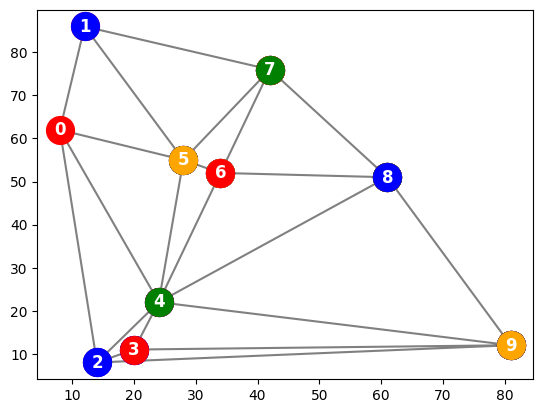

In [16]:
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")

for i in range(len(points)):
        plt.plot(points[i:,0], points[i:,1], 'o', color = list(res.values())[i], markersize = 20)
        plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.